In [1]:
!pip install -q --upgrade kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 3.9 MB/s eta 0:00:00


In [2]:
!kaggle datasets download -d isuruprabath/brfss-2023-csv-dataset

Dataset URL: https://www.kaggle.com/datasets/isuruprabath/brfss-2023-csv-dataset
License(s): CC0-1.0
100% 54.8M/54.8M [00:00<00:00, 137MB/s]



In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

project_path = "/content/drive/MyDrive/health-risk-prediction"
os.makedirs(project_path, exist_ok=True)
print("Project folder ready at:", project_path)

Project folder ready at: /content/drive/MyDrive/health-risk-prediction


In [5]:
import zipfile

with zipfile.ZipFile("brfss-2023-csv-dataset.zip", "r") as zip_ref:
    zip_ref.extractall("/content/brfss_raw")

# List what files we actually got
for file in os.listdir("/content/brfss_raw"):
    print(file)

BRFSS2023.csv


# PurvAarogya: Multi-Risk Health Screening

I predict Diabetes, Cardiovascular Disease and Stroke separately from the same 13 survey answers. It is a screening tool, not a diagnosis.

**Data:** CDC BRFSS 2023 (Behavioral Risk Factor Surveillance System), downloaded from Kaggle: https://www.kaggle.com/datasets/isuruprabath/brfss-2023-csv-dataset (license CC0-1.0, 433,323 rows x 350 columns).

**Steps:** targets, features, cleaning, split, EDA, feature selection, baseline, models, tuning, evaluation, interpretation, saving the models for the Streamlit app.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [7]:
# Load the raw CSV
df = pd.read_csv("/content/brfss_raw/BRFSS2023.csv")

# Basic shape and structure check
print("Shape (rows, columns):", df.shape)
print("\nFirst 5 column names:", df.columns[:5].tolist())
print("Last 5 column names:", df.columns[-5:].tolist())

Shape (rows, columns): (433323, 350)

First 5 column names: ['_state', 'fmonth', 'idate', 'imonth', 'iday']
Last 5 column names: ['_pneumo3', '_aidtst4', '_rfseat2', '_rfseat3', '_drnkdrv']


In [8]:
# saving a fast copy of the raw data to Drive, so next time I can skip the download and unzip
df.to_parquet(project_path + "/BRFSS2023.parquet")
print("Saved. Now load it with: pd.read_parquet(project_path + '/BRFSS2023.parquet')")

Saved. Now load it with: pd.read_parquet(project_path + '/BRFSS2023.parquet')


In [9]:
# Search for columns related to our 3 target conditions
diabetes_cols = [col for col in df.columns if "diabet" in col.lower()]
cvd_cols = [col for col in df.columns if "cvd" in col.lower() or "michd" in col.lower()]
stroke_cols = [col for col in df.columns if "strk" in col.lower() or "stroke" in col.lower()]

print("Diabetes-related columns:", diabetes_cols)
print("CVD-related columns:", cvd_cols)
print("Stroke-related columns:", stroke_cols)

Diabetes-related columns: ['diabete4']
CVD-related columns: ['cvdinfr4', 'cvdcrhd4', 'cvdstrk3', '_michd']
Stroke-related columns: ['cvdstrk3']


In [10]:
target_related_cols = ["diabete4", "cvdinfr4", "cvdcrhd4", "cvdstrk3", "_michd"]

for col in target_related_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- diabete4 ---
diabete4
3.0    358706
1.0     59786
4.0     10594
2.0      3253
7.0       683
9.0       296
NaN         5
Name: count, dtype: int64

--- cvdinfr4 ---
cvdinfr4
2.0    407304
1.0     23451
7.0      2314
9.0       251
NaN         3
Name: count, dtype: int64

--- cvdcrhd4 ---
cvdcrhd4
2.0    405638
1.0     23454
7.0      3936
9.0       292
NaN         3
Name: count, dtype: int64

--- cvdstrk3 ---
cvdstrk3
2.0    413499
1.0     18350
7.0      1212
9.0       258
NaN         4
Name: count, dtype: int64

--- _michd ---
_michd
2.0    392427
1.0     36311
NaN      4585
Name: count, dtype: int64


## Defining the target variables

One binary target per disease: diabetes from diabete4 (pre-diabetes counts as positive, because this is a risk tool), CVD from _michd (CDC already combined heart attack and coronary heart disease) and stroke from cvdstrk3.

Rows with don't know / refused answers are dropped: 433,323 to 427,034 rows (1.5% lost).

Positives: diabetes 68,857 (16.1%), CVD 35,958 (8.4%), stroke 17,819 (4.2%).

In [11]:
# making a copy so the raw dataframe stays untouched
data = df.copy()

# diabete4: 1 = yes, 2 = yes (only during pregnancy), 3 = no, 4 = pre-diabetes, 7/9 = unknown
# 1 and 4 are positive, 2 and 3 are negative (pregnancy-only is not chronic diabetes), 7/9 become nan
data["diabetes_target"] = data["diabete4"].map({1: 1, 4: 1, 3: 0, 2: 0})

# _michd: 1 = yes (heart attack or coronary heart disease), 2 = no
data["cvd_target"] = data["_michd"].map({1: 1, 2: 0})

# cvdstrk3: 1 = yes, 2 = no, 7/9 = unknown
data["stroke_target"] = data["cvdstrk3"].map({1: 1, 2: 0})

# drop rows where any target is unknown
data = data.dropna(subset=["diabetes_target", "cvd_target", "stroke_target"])

print("Rows remaining after cleaning targets:", data.shape[0])
print("\nDiabetes target distribution:\n", data["diabetes_target"].value_counts())
print("\nCVD target distribution:\n", data["cvd_target"].value_counts())
print("\nStroke target distribution:\n", data["stroke_target"].value_counts())

Rows remaining after cleaning targets: 427034

Diabetes target distribution:
 diabetes_target
0.0    358177
1.0     68857
Name: count, dtype: int64

CVD target distribution:
 cvd_target
0.0    391076
1.0     35958
Name: count, dtype: int64

Stroke target distribution:
 stroke_target
0.0    409215
1.0     17819
Name: count, dtype: int64


## Choosing features

I am not using all 350 columns. Many of them are survey admin details (interview date, state, etc), not health information.

Some columns would leak the answer. cvdinfr4 and cvdcrhd4 are already inside _michd, and diabage4 (age when told about diabetes) only exists if the person has diabetes. The model would just cheat.

Some columns are calculated versions of others (BMI from height and weight), so I keep only one version of each.

In [12]:
# Searching for candidate risk-factor columns by keyword, instead of guessing exact names
keywords = ["bmi", "genhlth", "smoke", "smoker", "alcohol", "drnk", "exer", "totinda",
            "sleptim", "menthlth", "physhlth", "bphigh", "bpmed", "chol", "age", "sex", "income", "educa"]

candidate_cols = []
for kw in keywords:
    matches = [col for col in data.columns if kw in col.lower()]
    print(f"'{kw}' matches:", matches)
    candidate_cols.extend(matches)

print("\nTotal matched columns (with duplicates):", len(candidate_cols))

'bmi' matches: ['_bmi5', '_bmi5cat', '_rfbmi5']
'genhlth' matches: ['genhlth']
'smoke' matches: ['smoke100', '_smoker3']
'smoker' matches: ['_smoker3']
'alcohol' matches: []
'drnk' matches: ['avedrnk3', 'drnk3ge5', 'maxdrnks', 'drnkdri2', 'drnkany6', '_drnkwk2', '_drnkdrv']
'exer' matches: ['exerany2', 'exeroft1', 'exerhmm1', 'exeroft2', 'exerhmm2', 'arthexer']
'totinda' matches: ['_totinda']
'sleptim' matches: []
'menthlth' matches: ['menthlth']
'physhlth' matches: ['physhlth']
'bphigh' matches: ['bphigh6']
'bpmed' matches: ['bpmeds1']
'chol' matches: ['cholchk3', 'cholmed3', '_cholch3', '_rfchol3']
'age' matches: ['diabage4', 'cncrage', 'cageg', '_ageg5yr', '_age65yr', '_age80', '_age_g']
'sex' matches: ['landsex2', 'cellsex2', 'sexvar', 'birthsex', 'acehvsex', '_sex']
'income' matches: ['income3']
'educa' matches: ['educa', '_educag']

Total matched columns (with duplicates): 45


## Final features

I picked one version of each variable and preferred the calculated "_" columns that CDC already cleaned. There is no sleep column in this file.

| Feature | Meaning | Coding |
|---|---|---|
| genhlth | general health | 1 excellent ... 5 poor |
| _bmi5 | BMI | stored x 100, I divide by 100 |
| _smoker3 | smoking | 1 every day, 2 some days, 3 former, 4 never |
| _drnkwk2 | drinks per week | stored x 100, I divide by 100 |
| _totinda | physical activity in last 30 days | 1 yes, 2 no |
| menthlth | days of poor mental health (last 30) | 0 to 30, 88 = zero days |
| physhlth | days of poor physical health (last 30) | 0 to 30, 88 = zero days |
| bphigh6 | high blood pressure | 0 no, 1 borderline, 2 yes (recoded below) |
| _rfchol3 | high cholesterol | 1 no, 2 yes |
| _ageg5yr | age group | 1 (18-24) ... 13 (80+) |
| _sex | sex | 1 male, 2 female |
| income3 | household income | 1 lowest ... 11 highest |
| _educag | education | 1 no high school ... 4 college graduate |

Meanings are from the CDC BRFSS codebook. For _totinda, _rfchol3 and _sex I also checked the direction with the disease rates further down.

In [13]:
candidate_features = [
    "genhlth", "_bmi5", "_smoker3", "_drnkwk2", "_totinda",
    "menthlth", "physhlth", "bphigh6", "_rfchol3",
    "_ageg5yr", "_sex", "income3", "_educag"
]

# confirm all these columns actually exist in our dataframe
missing = [col for col in candidate_features if col not in data.columns]
print("Missing columns :", missing)

# Peek at how much missing data (NaN) each candidate feature has
print("\nMissing value count per feature:")
print(data[candidate_features].isna().sum())

Missing columns : []

Missing value count per feature:
genhlth         2
_bmi5       39513
_smoker3        0
_drnkwk2        0
_totinda        0
menthlth        1
physhlth        1
bphigh6         0
_rfchol3    50587
_ageg5yr        0
_sex            0
income3      7922
_educag         0
dtype: int64


## Hidden missing values

BRFSS has no blanks for unknown answers, it uses codes like 7, 9, 77 and 99. In menthlth and physhlth the code 88 means zero days (about 59% of people), so it is a real answer.

What I found: genhlth 1,158 (7, 9, blank), _smoker3 22,455 (code 9), _drnkwk2 32,033 (99900), _bmi5 39,513 blanks, bphigh6 4,845 (2 = pregnancy only, 7, 9), _ageg5yr 7,415 (code 14), income3 84,300 (77, 99, blanks), menthlth 7,666, physhlth 10,217.

_bmi5 and _drnkwk2 are stored x 100 (the drinks values 23, 47, 70, 93 match 1 to 4 drinks a month as a weekly rate), so I divide both by 100.

In [14]:
for col in candidate_features:
    print(f"{col}")
    print(data[col].value_counts(dropna=False).sort_index())

genhlth
genhlth
1.0     63017
2.0    141103
3.0    142072
4.0     60226
5.0     19458
7.0       835
9.0       321
NaN         2
Name: count, dtype: int64
_bmi5
_bmi5
1202.0        3
1207.0        1
1208.0        1
1209.0        1
1211.0        3
          ...  
9921.0        1
9979.0        1
9982.0        1
9984.0        1
NaN       39513
Name: count, Length: 4074, dtype: int64
_smoker3
_smoker3
1     31134
2     13104
3    111341
4    249000
9     22455
Name: count, dtype: int64
_drnkwk2
_drnkwk2
0        187792
23        22320
47        19071
70         8606
93        12315
          ...  
49000         1
51100         1
52500         1
53200         3
99900     32033
Name: count, Length: 253, dtype: int64
_totinda
_totinda
1    321537
2    104381
9      1116
Name: count, dtype: int64
menthlth
menthlth
1.0      14028
2.0      23620
3.0      15237
4.0       7704
5.0      19742
6.0       2239
7.0       7598
8.0       1710
9.0        272
10.0     15229
11.0       130
12.0      1190
13.

In [15]:
# Fixing the "88 = zero days" special case FIRST, before we mark other codes as missing
data["menthlth"] = data["menthlth"].replace(88, 0)
data["physhlth"] = data["physhlth"].replace(88, 0)

# Fixing BMI scaling (BRFSS stores it as BMI * 100)
data["_bmi5"] = data["_bmi5"] / 100

# Now replacing all "don't know / refused / not applicable" codes with NaN so we can handle them properly
data["genhlth"] = data["genhlth"].replace([7, 9], np.nan)
data["_smoker3"] = data["_smoker3"].replace(9, np.nan)
data["_drnkwk2"] = data["_drnkwk2"].replace(99900, np.nan)
data["_drnkwk2"] = data["_drnkwk2"] / 100   # stored as drinks per week x 100
data["_totinda"] = data["_totinda"].replace(9, np.nan)
data["menthlth"] = data["menthlth"].replace([77, 99], np.nan)
data["physhlth"] = data["physhlth"].replace([77, 99], np.nan)
data["bphigh6"] = data["bphigh6"].replace([2, 7, 9], np.nan)
data["_rfchol3"] = data["_rfchol3"].replace(9, np.nan)
data["income3"] = data["income3"].replace([77, 99], np.nan)
data["_educag"] = data["_educag"].replace(9, np.nan)
data["_ageg5yr"] = data["_ageg5yr"].replace(14, np.nan)

print("Missing values per feature after cleaning:")
print(data[candidate_features].isna().sum())
print("\nTotal rows:", data.shape[0])

Missing values per feature after cleaning:
genhlth      1158
_bmi5       39513
_smoker3    22455
_drnkwk2    32033
_totinda     1116
menthlth     7666
physhlth    10217
bphigh6      4845
_rfchol3    53604
_ageg5yr     7415
_sex            0
income3     84300
_educag      2117
dtype: int64

Total rows: 427034


## Handling missing values

Under 5% missing: drop those rows. 5% or more: fill after the split, using the training data only, so nothing from the test set leaks in.

| Column | Missing | Treatment |
|---|---|---|
| genhlth | 0.27% | drop rows |
| _totinda | 0.26% | drop rows |
| _educag | 0.5% | drop rows |
| bphigh6 | 1.1% | drop rows |
| _ageg5yr | 1.7% | drop rows |
| menthlth | 1.8% | drop rows |
| physhlth | 2.4% | drop rows |
| _smoker3 | 5.3% | most frequent |
| _drnkwk2 | 7.5% | median |
| _bmi5 | 9.3% | median |
| _rfchol3 | 12.6% | most frequent |
| income3 | 19.7% | most frequent |

Dropping removed 29,556 rows (6.9%), leaving 397,478. The positive rates stayed about the same (training set 15.95% / 8.31% / 4.05%).

In [16]:
low_missing_cols = ["genhlth", "_totinda", "menthlth", "physhlth", "bphigh6", "_educag", "_ageg5yr"]
data = data.dropna(subset=low_missing_cols)

print("Rows remaining after dropping low-missingness rows:", data.shape[0])

# the other 5 columns still have nan, they get filled after the split
print("\nMissing values remaining:")
print(data[candidate_features].isna().sum())

Rows remaining after dropping low-missingness rows: 397478

Missing values remaining:
genhlth         0
_bmi5       32559
_smoker3    19427
_drnkwk2    27751
_totinda        0
menthlth        0
physhlth        0
bphigh6         0
_rfchol3    47732
_ageg5yr        0
_sex            0
income3     72016
_educag         0
dtype: int64


In [17]:
# bphigh6: 3 = no, 4 = borderline, 1 = yes. disease rate goes no < borderline < yes, so I put them in that order
# the assert stops this cell from running twice by mistake (it would scramble the values)
assert set(data["bphigh6"].unique()) <= {1.0, 3.0, 4.0}
data["bphigh6"] = data["bphigh6"].map({3: 0, 4: 1, 1: 2})
print(data["bphigh6"].value_counts())

bphigh6
0    232278
2    161431
1      3769
Name: count, dtype: int64


In [18]:
print("Duplicate rows:", data.duplicated().sum())

Duplicate rows: 0


## Train test split

70/30, stratified on the 3 targets together so that stroke, the rarest, appears in both sets: 278,234 training rows and 119,244 test rows. The test set has 19,022 diabetes, 9,910 CVD and 4,832 stroke cases.

The test set stays untouched until the final evaluation. Imputation, scaling and tuning learn from the training set only.

In [19]:
from sklearn.model_selection import train_test_split

target_cols = ["diabetes_target", "cvd_target", "stroke_target"]

X = data[candidate_features]
y = data[target_cols]

# joining the 3 targets into one label so stratify keeps all of them balanced
strat_key = (y["diabetes_target"].astype(int).astype(str)
             + y["cvd_target"].astype(int).astype(str)
             + y["stroke_target"].astype(int).astype(str))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=strat_key)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (278234, 13) Test: (119244, 13)


In [20]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

median_cols = ["_bmi5", "_drnkwk2"]
mode_cols = ["_smoker3", "_rfchol3", "income3"]

imputer = ColumnTransformer(
    [("median", SimpleImputer(strategy="median"), median_cols),
     ("mode", SimpleImputer(strategy="most_frequent"), mode_cols)],
    remainder="passthrough",
    verbose_feature_names_out=False)
imputer.set_output(transform="pandas")

# learn the median / mode from train only, then apply to both
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

print("Missing left in train:", X_train.isna().sum().sum())
print("Missing left in test:", X_test.isna().sum().sum())

Missing left in train: 0
Missing left in test: 0


diabetes_target    15.95
cvd_target          8.31
stroke_target       4.05
dtype: float64


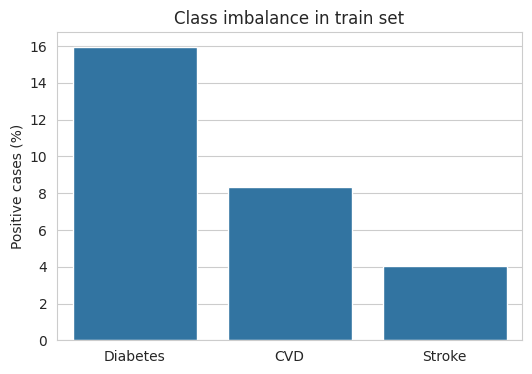

In [21]:
positive_rate = y_train.mean() * 100
print(positive_rate.round(2))

plt.figure(figsize=(6, 4))
sns.barplot(x=["Diabetes", "CVD", "Stroke"], y=positive_rate.values)
plt.ylabel("Positive cases (%)")
plt.title("Class imbalance in train set")
plt.show()

### Observation: class imbalance

Positives in the training set: diabetes 15.95%, CVD 8.31%, stroke 4.05%. Saying "no disease" for everyone is already right 84%, 92% and 96% of the time, so I judge the models on recall, F1 and ROC-AUC and not on accuracy.

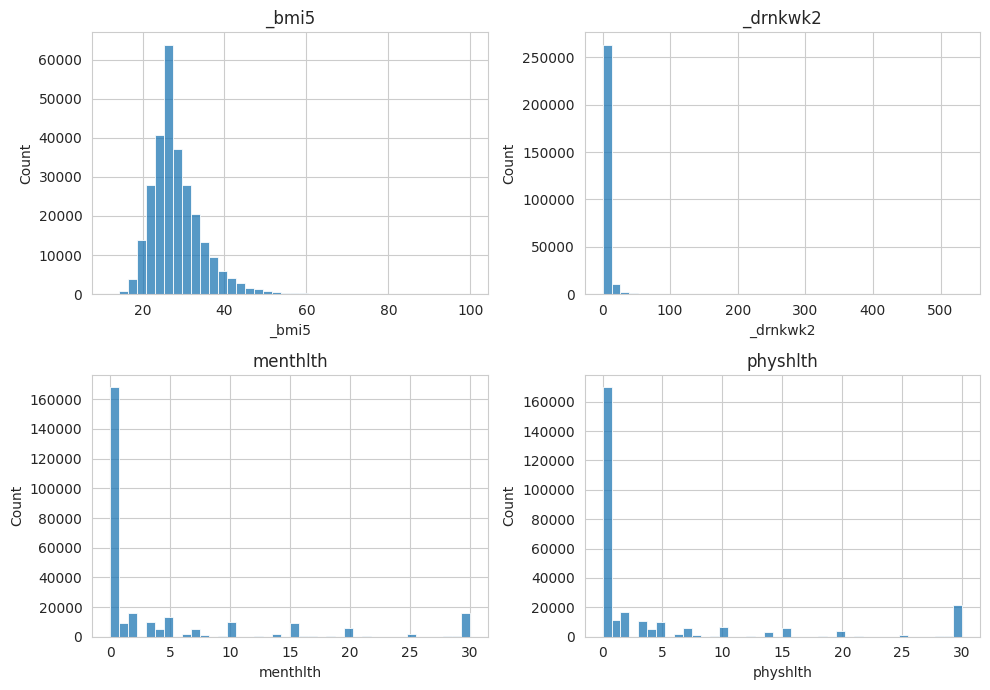

           _bmi5   _drnkwk2   menthlth   physhlth
count  278234.00  278234.00  278234.00  278234.00
mean       28.38       2.69       4.30       4.39
std         6.24       7.95       8.22       8.73
min        12.07       0.00       0.00       0.00
25%        24.37       0.00       0.00       0.00
50%        27.40       0.23       0.00       0.00
75%        31.17       2.10       5.00       3.00
max        99.84     532.00      30.00      30.00


In [22]:
num_cols = ["_bmi5", "_drnkwk2", "menthlth", "physhlth"]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(X_train[col], bins=40, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

print(X_train[num_cols].describe().round(2))

### Observation: numeric features

- BMI: median 27.4, most people between 24 and 31, long tail to the right up to 99.8.
- Drinks per week: median 0.23 and mean 2.7, but the maximum is 532 per week (about 76 drinks a day), which is not possible. I use log1p on this column in the pipeline.
- menthlth and physhlth: more than half answered 0 days and there is a second spike at 30, so they are skewed counts of days.

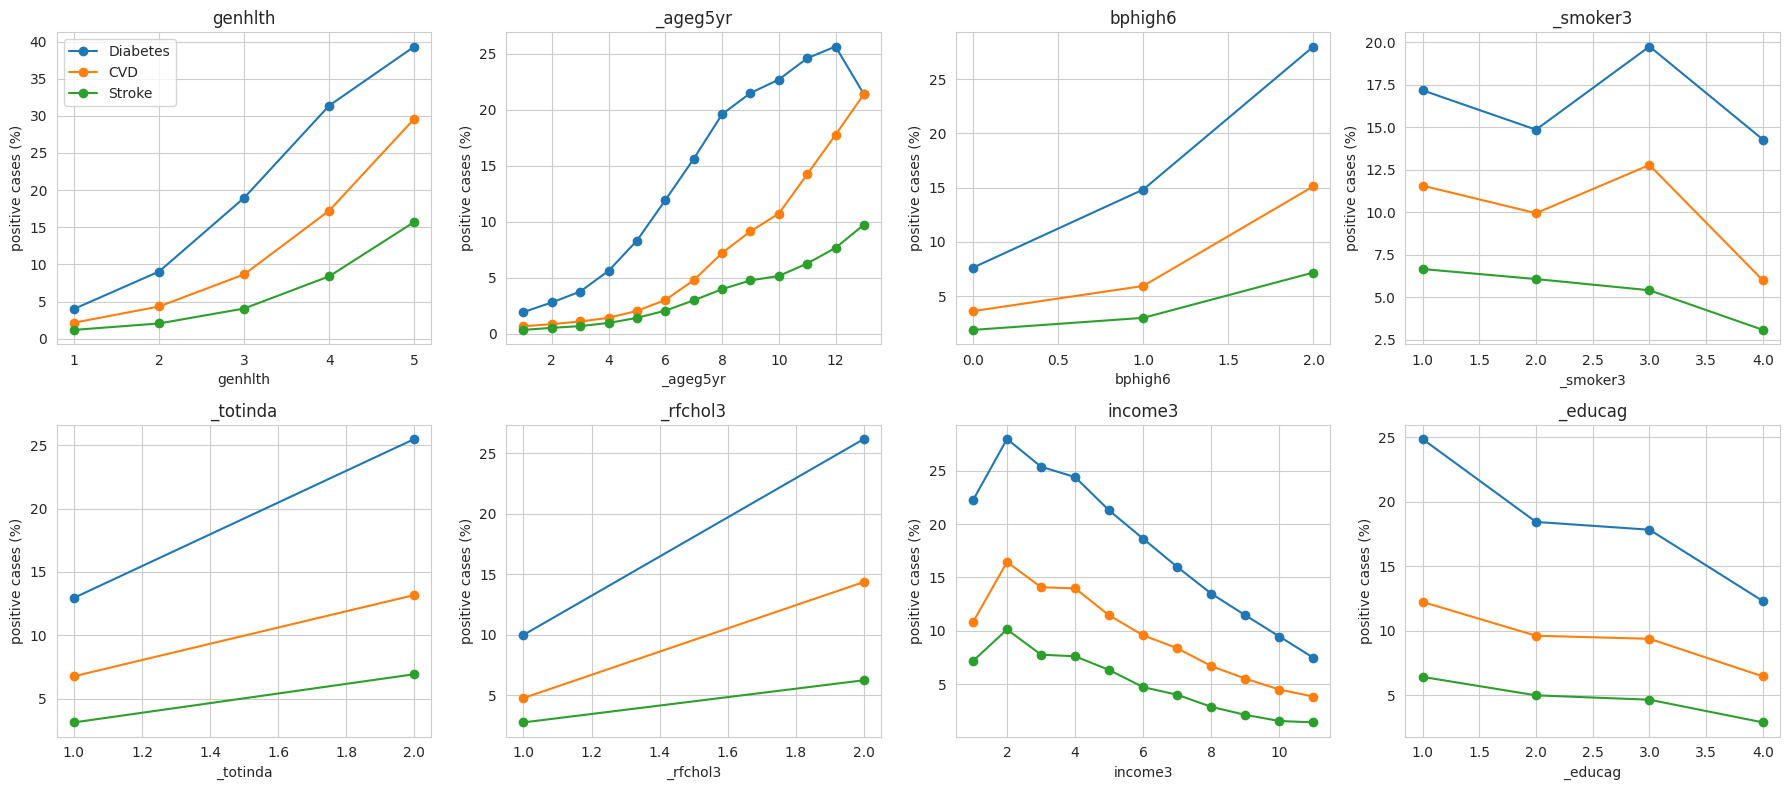

In [23]:
train = X_train.join(y_train)

cat_cols = ["genhlth", "_ageg5yr", "bphigh6", "_smoker3", "_totinda", "_rfchol3", "income3", "_educag"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), cat_cols):
    rates = train.groupby(col)[target_cols].mean() * 100
    rates.plot(ax=ax, marker="o", legend=False)
    ax.set_title(col)
    ax.set_ylabel("positive cases (%)")
axes[0, 0].legend(["Diabetes", "CVD", "Stroke"])
plt.tight_layout()
plt.show()

### Observation: disease rate by category

- Rates rise steadily with worse general health (diabetes 4% to 39%), age (diabetes 2% to 25%, CVD under 1% to 21%) and blood pressure (diabetes 7.5% / 14.8% / 28% for no / borderline / yes, which is why I ordered bphigh6 that way).
- Rates fall as income and education rise (diabetes from about 28% to 7.5% across income groups 2 to 11).
- _totinda code 2 and _rfchol3 code 2 have about double the diabetes rate of code 1 (25.5% vs 13% and 26% vs 10%), so code 2 means not active / high cholesterol.
- _smoker3 has no clean order (former smokers highest, never smoked lowest), so I one-hot it.

In [24]:
# checking which code means what, using the disease rates (train only)
for col in ["_rfchol3", "_totinda", "_sex"]:
    print(col)
    print((train.groupby(col)[target_cols].mean() * 100).round(1))
    print()

_rfchol3
          diabetes_target  cvd_target  stroke_target
_rfchol3                                            
1.0                  10.0         4.8            2.8
2.0                  26.2        14.4            6.3

_totinda
          diabetes_target  cvd_target  stroke_target
_totinda                                            
1.0                  13.0         6.8            3.1
2.0                  25.5        13.2            6.9

_sex
      diabetes_target  cvd_target  stroke_target
_sex                                            
1                16.5        10.4            4.1
2                15.5         6.4            4.0



Sex check: code 1 has more CVD (10.4% vs 6.4%) and about the same diabetes (16.5% vs 15.5%) and stroke (4.1% vs 4.0%), which fits 1 = male.

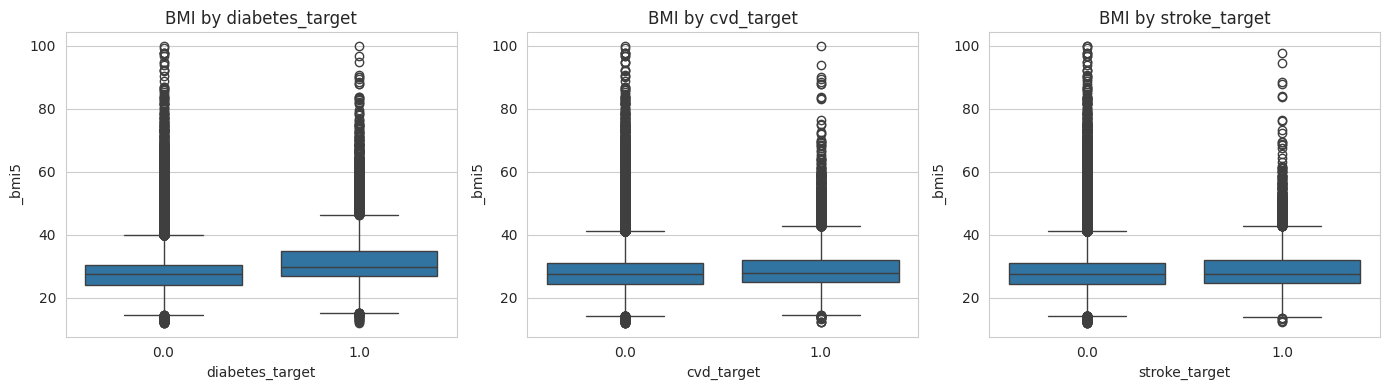

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, t in zip(axes, target_cols):
    sns.boxplot(x=train[t], y=train["_bmi5"], ax=ax)
    ax.set_title("BMI by " + t)
plt.tight_layout()
plt.show()

In [26]:
# counting outliers with the IQR rule (train only)
for col in ["_bmi5", "_drnkwk2", "menthlth", "physhlth"]:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n_out = ((X_train[col] < low) | (X_train[col] > high)).sum()
    print(f"{col}: {n_out} outliers ({n_out / len(X_train) * 100:.1f}%), max value = {X_train[col].max()}")

_bmi5: 10889 outliers (3.9%), max value = 99.84
_drnkwk2: 41398 outliers (14.9%), max value = 532.0
menthlth: 37460 outliers (13.5%), max value = 30.0
physhlth: 46454 outliers (16.7%), max value = 30.0


## Outliers

IQR rule on the training set: BMI 3.9%, drinks 14.9%, menthlth 13.5%, physhlth 16.7% of rows.

- BMI: values up to 99.8 are rare but possible, and a very high BMI is exactly the high-risk group, so I keep them.
- Drinks: the IQR rule flags 14.9% only because most people drink very little (upper limit about 5 per week), and normal heavier drinkers are not errors. Only the extreme values (up to 532 per week) are impossible. I keep them because log1p squeezes them, and the app will limit this input to a sensible range.
- menthlth and physhlth: values are 0 to 30 by definition, so the IQR count only shows that most answers are 0. Nothing to remove.

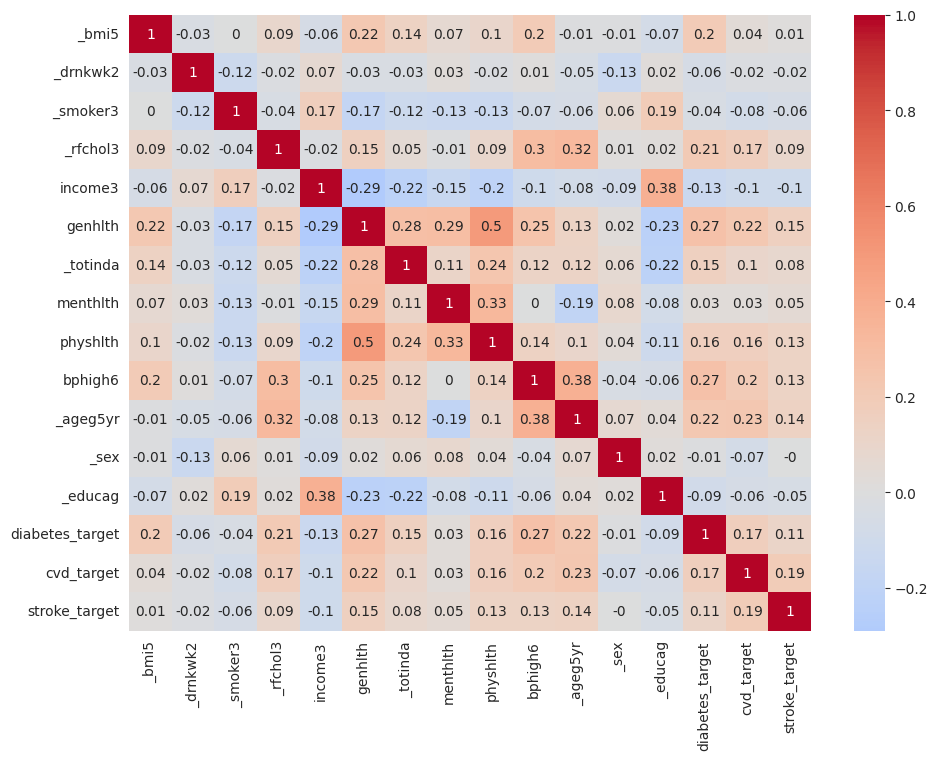

In [27]:
plt.figure(figsize=(11, 8))
sns.heatmap(train.corr().round(2), annot=True, cmap="coolwarm", center=0)
plt.show()

### Observation: correlations

- Links with the targets are small: genhlth (0.27 diabetes, 0.22 CVD), bphigh6 (0.27, 0.20), age group (0.22, 0.23, 0.14 stroke), _rfchol3 (0.21 diabetes), BMI (0.20 diabetes). No single feature predicts a disease alone.
- Between features the highest are genhlth and physhlth (0.50), income3 and _educag (0.38), bphigh6 and age (0.38). Nothing is above 0.5, so multicollinearity is not a big worry.
- The targets correlate only weakly with each other (0.11 to 0.19), so three separate models make sense.
- _sex is almost unrelated to the targets (-0.01, -0.07, 0.00). Drinks is slightly negative, maybe because people who get sick drink less, but this data cannot show that.

## Feature selection

Ranking the 13 features on the training set only: ANOVA F-score for numeric columns (does the average differ between sick and healthy people?) and chi-square turned into Cramér's V (0 to 1) for categorical columns.

- Strongest: genhlth (V 0.27 / 0.24 / 0.17 for diabetes / CVD / stroke), bphigh6 (0.27 / 0.20 / 0.13), age group (0.23 / 0.24 / 0.14) and physhlth (F 7,074 / 7,602 / 4,850). BMI is very strong for diabetes (F 11,708) but weak for stroke (53).
- Weakest: _sex (V 0.013 for diabetes, 0.002 for stroke), then _smoker3, _educag and drinks.

I keep all 13: it is a small set, and these scores look at one feature at a time. A weak feature can still help in combination with others (_sex has V 0.073 for CVD).

In [28]:
from scipy.stats import chi2_contingency
from sklearn.feature_selection import f_classif

num_cols = ["_bmi5", "_drnkwk2", "menthlth", "physhlth"]
cat_cols = [c for c in X_train.columns if c not in num_cols]

# anova f-score for numeric features, one column per target
anova_scores = pd.DataFrame(index=num_cols)
for t in target_cols:
    f_vals, p_vals = f_classif(X_train[num_cols], y_train[t])
    anova_scores[t] = f_vals

# chi-square for categorical features, cramer's v makes the scores comparable
chi_scores = pd.DataFrame(index=cat_cols)
for t in target_cols:
    v_list = []
    for col in cat_cols:
        table = pd.crosstab(X_train[col], y_train[t])
        chi2, p, dof, expected = chi2_contingency(table)
        v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
        v_list.append(v)
    chi_scores[t] = v_list

print("ANOVA F-scores (numeric features):")
print(anova_scores.round(1))
print("\nCramer's V (categorical features):")
print(chi_scores.round(3))

ANOVA F-scores (numeric features):
          diabetes_target  cvd_target  stroke_target
_bmi5             11708.4       356.7           52.6
_drnkwk2           1099.2        92.6           64.0
menthlth            302.7       233.1          620.7
physhlth           7074.0      7602.2         4850.1

Cramer's V (categorical features):
          diabetes_target  cvd_target  stroke_target
_smoker3            0.065       0.112          0.066
_rfchol3            0.213       0.168          0.085
income3             0.132       0.105          0.100
genhlth             0.269       0.235          0.169
_totinda            0.146       0.099          0.082
bphigh6             0.272       0.204          0.131
_ageg5yr            0.226       0.241          0.144
_sex                0.013       0.073          0.002
_educag             0.097       0.063          0.056


## Baseline model

Plain Logistic Regression with default settings, inside a pipeline (log1p + scaling for drinks, one-hot for smoker, scaling for the rest), so everything is learned from the training set only.

| Target | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Diabetes | 0.845 | 0.547 | 0.182 | 0.273 | 0.811 |
| CVD | 0.917 | 0.500 | 0.065 | 0.115 | 0.834 |
| Stroke | 0.959 | 0.333 | 0.000 | 0.001 | 0.802 |

Accuracy is misleading: for stroke the model reaches 0.959 with almost no recall, because it says "no stroke" for nearly everyone. ROC-AUC is decent (0.80 to 0.83), so the ranking is good but the 0.5 cut-off is too high for rare diseases. Next: handle the imbalance.

In [29]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

drink_col = ["_drnkwk2"]
onehot_cols = ["_smoker3"]
scale_cols = [c for c in X_train.columns if c not in drink_col + onehot_cols]

# log1p squeezes the huge drink values, then scale. smoker is a category so one-hot. the rest just get scaled
prep = ColumnTransformer([
    ("drinks", Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]), drink_col),
    ("smoker", OneHotEncoder(handle_unknown="ignore"), onehot_cols),
    ("scale", StandardScaler(), scale_cols)])

baseline_results = []
for t in target_cols:
    model = Pipeline([("prep", clone(prep)), ("lr", LogisticRegression(max_iter=1000))])
    model.fit(X_train, y_train[t].astype(int))

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    y_true = y_test[t].astype(int)

    baseline_results.append({
        "target": t,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "f1": f1_score(y_true, pred),
        "roc_auc": roc_auc_score(y_true, prob)})

baseline_df = pd.DataFrame(baseline_results).set_index("target")
print(baseline_df.round(3))

                 accuracy  precision  recall     f1  roc_auc
target                                                      
diabetes_target     0.845      0.547   0.182  0.273    0.811
cvd_target          0.917      0.500   0.065  0.115    0.834
stroke_target       0.959      0.333   0.000  0.001    0.802


## Handling class imbalance

Two options on the same Logistic Regression: class_weight="balanced" (missing a sick person costs more) and SMOTE (synthetic sick examples, inside the pipeline so only the training data is touched).

| Target | Method | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Diabetes | baseline | 0.547 | 0.182 | 0.273 | 0.811 |
| Diabetes | class_weight | 0.337 | 0.763 | 0.468 | 0.811 |
| Diabetes | SMOTE | 0.338 | 0.760 | 0.468 | 0.811 |
| CVD | baseline | 0.500 | 0.065 | 0.115 | 0.834 |
| CVD | class_weight | 0.207 | 0.794 | 0.328 | 0.834 |
| CVD | SMOTE | 0.208 | 0.789 | 0.329 | 0.834 |
| Stroke | baseline | 0.333 | 0.000 | 0.001 | 0.802 |
| Stroke | class_weight | 0.097 | 0.772 | 0.172 | 0.802 |
| Stroke | SMOTE | 0.097 | 0.766 | 0.172 | 0.800 |

Both methods give almost the same result: recall goes from nearly 0 to about 0.76-0.79, precision drops, and accuracy falls to about 0.70-0.73 because more healthy people are flagged. ROC-AUC stays the same because it ignores the cut-off.

Decision: class weights. Same result, simpler, no made-up rows. Side effect: the average score for diabetes is 0.40 while the real rate is 0.16, so the scores are not probabilities and the app shows a risk flag.

In [30]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

def get_scores(model, X_te, y_te):
    pred = model.predict(X_te)
    prob = model.predict_proba(X_te)[:, 1]
    return {"accuracy": accuracy_score(y_te, pred),
            "precision": precision_score(y_te, pred, zero_division=0),
            "recall": recall_score(y_te, pred),
            "f1": f1_score(y_te, pred),
            "roc_auc": roc_auc_score(y_te, prob)}

imbalance_results = []
for t in target_cols:
    y_tr = y_train[t].astype(int)
    y_te = y_test[t].astype(int)

    # option 1: class weights
    cw_model = Pipeline([("prep", clone(prep)),
                         ("lr", LogisticRegression(max_iter=1000, class_weight="balanced"))])
    cw_model.fit(X_train, y_tr)
    row = get_scores(cw_model, X_test, y_te)
    row.update(target=t, method="class_weight")
    imbalance_results.append(row)

    # option 2: SMOTE, only applied on training data because it is inside the pipeline
    sm_model = ImbPipeline([("prep", clone(prep)),
                            ("smote", SMOTE(random_state=42)),
                            ("lr", LogisticRegression(max_iter=1000))])
    sm_model.fit(X_train, y_tr)
    row = get_scores(sm_model, X_test, y_te)
    row.update(target=t, method="smote")
    imbalance_results.append(row)

# putting the baseline rows in the same table
base_rows = baseline_df.reset_index().assign(method="baseline")
compare_df = pd.concat([base_rows, pd.DataFrame(imbalance_results)])
compare_df = compare_df.set_index(["target", "method"]).sort_index()
print(compare_df.round(3))

                              accuracy  precision  recall     f1  roc_auc
target          method                                                   
cvd_target      baseline         0.917      0.500   0.065  0.115    0.834
                class_weight     0.730      0.207   0.794  0.328    0.834
                smote            0.733      0.208   0.789  0.329    0.834
diabetes_target baseline         0.845      0.547   0.182  0.273    0.811
                class_weight     0.723      0.337   0.763  0.468    0.811
                smote            0.724      0.338   0.760  0.468    0.811
stroke_target   baseline         0.959      0.333   0.000  0.001    0.802
                class_weight     0.699      0.097   0.772  0.172    0.802
                smote            0.700      0.097   0.766  0.172    0.800


## Random Forest and XGBoost

Two tree models to catch non-linear effects: Random Forest (100 trees, depth 12, min leaf 50, balanced_subsample) and XGBoost (scale_pos_weight = healthy / sick). They need no scaling.

Test ROC-AUC:

| Target | Logistic Reg. | Random Forest | XGBoost |
|---|---|---|---|
| Diabetes | 0.811 | 0.817 | 0.818 |
| CVD | 0.834 | 0.835 | 0.836 |
| Stroke | 0.802 | 0.802 | 0.799 |

All three are within 0.007, so the 13 features, not the algorithm, are the limit.

In [31]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

tree_results = []
for t in target_cols:
    y_tr = y_train[t].astype(int)
    y_te = y_test[t].astype(int)

    # random forest, balanced_subsample = class weights recomputed for each tree's sample
    rf = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=50,
                                class_weight="balanced_subsample", n_jobs=-1, random_state=42)
    rf.fit(X_train, y_tr)
    row = get_scores(rf, X_test, y_te)
    row.update(target=t, method="random_forest")
    tree_results.append(row)

    # xgboost, scale_pos_weight = healthy count / sick count
    weight = (y_tr == 0).sum() / (y_tr == 1).sum()
    xgb = XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                        scale_pos_weight=weight, tree_method="hist",
                        n_jobs=-1, random_state=42)
    xgb.fit(X_train, y_tr)
    row = get_scores(xgb, X_test, y_te)
    row.update(target=t, method="xgboost")
    tree_results.append(row)

tree_df = pd.DataFrame(tree_results).set_index(["target", "method"])
compare_df = pd.concat([compare_df, tree_df]).sort_index()
print(compare_df.round(3))

                               accuracy  precision  recall     f1  roc_auc
target          method                                                    
cvd_target      baseline          0.917      0.500   0.065  0.115    0.834
                class_weight      0.730      0.207   0.794  0.328    0.834
                random_forest     0.739      0.212   0.788  0.334    0.835
                smote             0.733      0.208   0.789  0.329    0.834
                xgboost           0.729      0.207   0.801  0.330    0.836
diabetes_target baseline          0.845      0.547   0.182  0.273    0.811
                class_weight      0.723      0.337   0.763  0.468    0.811
                random_forest     0.720      0.337   0.779  0.470    0.817
                smote             0.724      0.338   0.760  0.468    0.811
                xgboost           0.715      0.334   0.789  0.469    0.818
stroke_target   baseline          0.959      0.333   0.000  0.001    0.802
                class_wei

## Hyperparameter tuning

GridSearchCV with 3-fold stratified cross-validation, scored on ROC-AUC, on a 50,000-row sample of the training set (for speed).

| Model | Search space | Chosen (all 3 targets) |
|---|---|---|
| Logistic Regression | C = 0.01, 0.1, 1, 10 | C = 0.01 |
| XGBoost | max_depth = 3, 5 and n_estimators = 100, 200 | depth 3, 100 trees |

| Target | CV ROC-AUC Logistic Reg. | CV ROC-AUC XGBoost |
|---|---|---|
| Diabetes | 0.805 | 0.805 |
| CVD | 0.832 | 0.826 |
| Stroke | 0.797 | 0.783 |

Random Forest was not tuned (fixed settings). The chosen values are the simplest in each grid and sit at its edge, so C = 0.001 or depth 2 might be slightly better. Logistic Regression is as good as or better than XGBoost in cross-validation.

In [32]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

for t in target_cols:
    y_tr = y_train[t].astype(int)
    weight = (y_tr == 0).sum() / (y_tr == 1).sum()

    # small sample just for the search, so it runs fast
    X_small, _, y_small, _ = train_test_split(
        X_train, y_tr, train_size=50000, stratify=y_tr, random_state=42)

    # model 1: logistic regression, tuning C
    lr_pipe = Pipeline([("prep", clone(prep)),
                        ("lr", LogisticRegression(max_iter=1000, class_weight="balanced"))])
    lr_search = GridSearchCV(lr_pipe, {"lr__C": [0.01, 0.1, 1, 10]}, scoring="roc_auc", cv=cv)
    lr_search.fit(X_small, y_small)

    # model 2: xgboost, tuning depth and number of trees
    xgb = XGBClassifier(scale_pos_weight=weight, tree_method="hist", random_state=42)
    xgb_search = GridSearchCV(xgb, {"max_depth": [3, 5], "n_estimators": [100, 200]},
                              scoring="roc_auc", cv=cv)
    xgb_search.fit(X_small, y_small)

    print(t)
    print("logreg :", lr_search.best_params_, round(lr_search.best_score_, 3))
    print("xgboost:", xgb_search.best_params_, round(xgb_search.best_score_, 3))

diabetes_target
  logreg : {'lr__C': 0.01} 0.805
  xgboost: {'max_depth': 3, 'n_estimators': 100} 0.805
cvd_target
  logreg : {'lr__C': 0.01} 0.832
  xgboost: {'max_depth': 3, 'n_estimators': 100} 0.826
stroke_target
  logreg : {'lr__C': 0.01} 0.797
  xgboost: {'max_depth': 3, 'n_estimators': 100} 0.783


## Final models and error analysis

Final model: Logistic Regression (C = 0.01, balanced), fitted on the whole training set and scored on the test set.

| Target | Real cases | Caught (TP) | Missed (FN) | Healthy flagged (FP) | Recall | Precision |
|---|---|---|---|---|---|---|
| Diabetes | 19,022 | 14,513 | 4,509 | 28,546 | 0.763 | 0.337 |
| CVD | 9,910 | 7,863 | 2,047 | 30,169 | 0.793 | 0.207 |
| Stroke | 4,832 | 3,731 | 1,101 | 34,800 | 0.772 | 0.097 |

- A missed sick person is the worse mistake for a screening tool, so I accept false alarms to catch 76-79% of real cases.
- The cost: about 2 healthy people flagged per real diabetes case caught, about 4 for CVD and about 9 for stroke. Flagged means "worth getting checked", not "sick".
- The average score (0.40, 0.36, 0.37) is far above the real rates (0.16, 0.083, 0.041), so the scores are not probabilities.

In [46]:
from sklearn.metrics import confusion_matrix

final_models = {}
xgb_final = {}
final_results = []

for t in target_cols:
    y_tr = y_train[t].astype(int)
    y_te = y_test[t].astype(int)
    weight = (y_tr == 0).sum() / (y_tr == 1).sum()

    # final logistic regression with the tuned C
    lr_model = Pipeline([("prep", clone(prep)),
                         ("lr", LogisticRegression(C=0.01, max_iter=1000, class_weight="balanced"))])
    lr_model.fit(X_train, y_tr)
    final_models[t] = lr_model

    # tuned xgboost, kept for the comparison table
    xgb_model = XGBClassifier(max_depth=3, n_estimators=100, scale_pos_weight=weight,
                              tree_method="hist", n_jobs=-1, random_state=42)
    xgb_model.fit(X_train, y_tr)
    xgb_final[t] = xgb_model

    for name, model in [("logreg_final", lr_model), ("xgboost_final", xgb_model)]:
        row = get_scores(model, X_test, y_te)
        row.update(target=t, method=name)
        final_results.append(row)

    # error analysis for the final logistic regression
    prob = lr_model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_te, lr_model.predict(X_test)).ravel()
    print(t)
    print("  missed sick people (FN):", fn, "| caught (TP):", tp)
    print("  healthy flagged (FP):", fp, "| correctly cleared (TN):", tn)
    print("  real positive rate:", round(y_te.mean(), 3),
          "| average predicted score:", round(prob.mean(), 3))

final_df = pd.DataFrame(final_results).set_index(["target", "method"])
print()
print(final_df.round(3))

diabetes_target
  missed sick people (FN): 4509 | caught (TP): 14513
  healthy flagged (FP): 28546 | correctly cleared (TN): 71676
  real positive rate: 0.16 | average predicted score: 0.402
cvd_target
  missed sick people (FN): 2047 | caught (TP): 7863
  healthy flagged (FP): 30169 | correctly cleared (TN): 79165
  real positive rate: 0.083 | average predicted score: 0.356
stroke_target
  missed sick people (FN): 1101 | caught (TP): 3731
  healthy flagged (FP): 34800 | correctly cleared (TN): 79612
  real positive rate: 0.041 | average predicted score: 0.372

                               accuracy  precision  recall     f1  roc_auc
target          method                                                    
diabetes_target logreg_final      0.723      0.337   0.763  0.468    0.811
                xgboost_final     0.713      0.332   0.790  0.468    0.817
cvd_target      logreg_final      0.730      0.207   0.793  0.328    0.834
                xgboost_final     0.723      0.204   0.808

In [47]:
from sklearn.model_selection import cross_val_score

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

param_text = {
    "baseline_logreg": "default (C=1)",
    "logreg_tuned": "C=0.01, balanced",
    "random_forest": "100 trees, depth 12, min_leaf 50 (not tuned)",
    "xgboost_tuned": "depth 3, 100 trees, scale_pos_weight"}

rows = []
for t in target_cols:
    y_tr = y_train[t].astype(int)
    y_te = y_test[t].astype(int)
    weight = (y_tr == 0).sum() / (y_tr == 1).sum()

    models = {
        "baseline_logreg": Pipeline([("prep", clone(prep)), ("lr", LogisticRegression(max_iter=1000))]),
        "logreg_tuned": Pipeline([("prep", clone(prep)),
                                  ("lr", LogisticRegression(C=0.01, max_iter=1000, class_weight="balanced"))]),
        "random_forest": RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=50,
                                                class_weight="balanced_subsample", n_jobs=-1, random_state=42),
        "xgboost_tuned": XGBClassifier(max_depth=3, n_estimators=100, scale_pos_weight=weight,
                                       tree_method="hist", n_jobs=-1, random_state=42)}

    for name, model in models.items():
        # validation result = cross-validation on the training set only
        cv_auc = cross_val_score(model, X_train, y_tr, cv=cv, scoring="roc_auc")
        # test result = fit on the full train set, score on the test set (just for reporting)
        model.fit(X_train, y_tr)
        row = get_scores(model, X_test, y_te)
        row.update(target=t, method=name, cv_auc=cv_auc.mean(), cv_std=cv_auc.std(),
                   best_params=param_text[name])
        rows.append(row)

test_cols = ["accuracy", "precision", "recall", "f1", "roc_auc"]
final_table = pd.DataFrame(rows).set_index(["target", "method"])
final_table = final_table.rename(columns={c: "test_" + c for c in test_cols})
show_cols = ["best_params", "cv_auc", "cv_std"] + ["test_" + c for c in test_cols]
print(final_table[show_cols].round(3).to_string())
final_table[show_cols].round(3).to_csv(project_path + "/model_comparison.csv")

                                                                  best_params  cv_auc  cv_std  test_accuracy  test_precision  test_recall  test_f1  test_roc_auc
target          method                                                                                                                                          
diabetes_target baseline_logreg                                 default (C=1)   0.811   0.001          0.845           0.547        0.182    0.273         0.811
                logreg_tuned                                 C=0.01, balanced   0.811   0.001          0.723           0.337        0.763    0.468         0.811
                random_forest    100 trees, depth 12, min_leaf 50 (not tuned)   0.817   0.002          0.720           0.337        0.779    0.470         0.817
                xgboost_tuned            depth 3, 100 trees, scale_pos_weight   0.818   0.001          0.713           0.332        0.790    0.468         0.817
cvd_target      baseline_logreg   

### Model comparison

Cross-validation ROC-AUC (3-fold on the full training set) and test ROC-AUC are almost the same for every model (logistic regression for diabetes 0.811 and 0.811), so there is no overfitting. All four models are within 0.007 ROC-AUC of each other.

Final choice: Logistic Regression (C = 0.01, balanced). It ties with XGBoost and Random Forest, is the simplest and fastest, and its coefficients can be explained.

Note: while comparing methods (class weights vs SMOTE, and the models) I also looked at test scores. The tuning itself used cross-validation only, and the cross-validation column shows the same ranking.

            diabetes_target  cvd_target  stroke_target
_drnkwk2               0.74        0.90           0.89
_smoker3_1             0.86        1.01           1.05
_smoker3_2             0.89        1.00           1.17
_smoker3_3             0.94        0.90           0.81
_smoker3_4             0.91        0.63           0.68
_bmi5                  1.52        1.00           0.96
_rfchol3               1.36        1.33           1.12
income3                0.93        0.90           0.82
genhlth                1.67        1.71           1.53
_totinda               1.08        1.02           1.05
menthlth               0.99        1.07           1.11
physhlth               0.97        1.09           1.12
bphigh6                1.44        1.37           1.37
_ageg5yr               1.71        2.70           2.22
_sex                   0.87        0.68           0.91
_educag                0.94        0.96           0.96


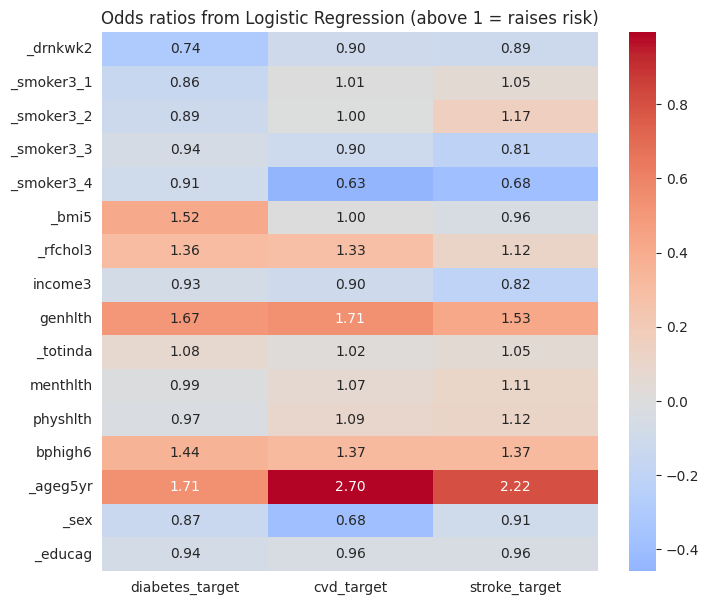

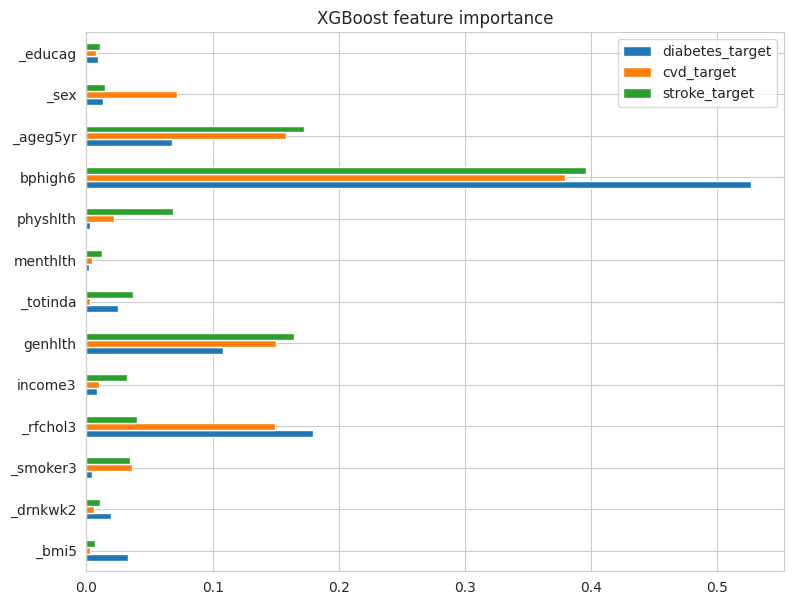

In [48]:
# column names after the preprocessing: drinks first, then smoker one-hot, then the scaled columns
ohe = final_models["diabetes_target"].named_steps["prep"].named_transformers_["smoker"]
smoker_names = ["_smoker3_" + str(int(c)) for c in ohe.categories_[0]]
feature_order = ["_drnkwk2"] + smoker_names + scale_cols

odds = pd.DataFrame(index=feature_order)
for t in target_cols:
    coef = final_models[t].named_steps["lr"].coef_[0]
    assert len(coef) == len(feature_order)
    odds[t] = np.exp(coef)    # odds ratio for a 1 standard deviation increase

print(odds.round(2))

plt.figure(figsize=(8, 7))
sns.heatmap(np.log(odds), annot=odds.values, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Odds ratios from Logistic Regression (above 1 = raises risk)")
plt.show()

# XGBoost importance, to compare with Logistic Regression
importance = pd.DataFrame({t: xgb_final[t].feature_importances_ for t in target_cols},
                          index=X_train.columns)
importance.plot(kind="barh", figsize=(9, 7), title="XGBoost feature importance")
plt.show()

### Interpretation

Logistic Regression odds ratios (per 1 standard deviation, above 1 = higher risk):
- Age group is the strongest (2.70 CVD, 2.22 stroke, 1.71 diabetes), then general health (1.67 / 1.71 / 1.53) and blood pressure (1.44 / 1.37 / 1.37). Cholesterol matters for diabetes and CVD (1.36, 1.33) and BMI only for diabetes (1.52).
- Never having smoked has the lowest odds for CVD and stroke (0.63 and 0.68). _sex has 0.68 for CVD, which fits the CVD gap seen in the EDA. Higher income lowers the risk a little (0.82 to 0.93).
- physhlth and menthlth have small ratios because general health already carries that information (correlation 0.50).
- Drinks have an odds ratio below 1 (0.74 for diabetes). I read this as an association and not as "drinking protects": people who get sick may cut down on alcohol.

XGBoost importance agrees on the group of leading features but puts blood pressure far above the rest (about 0.53 for diabetes and 0.4 for CVD and stroke), then cholesterol for diabetes (0.18), and age and general health for CVD and stroke. Trees favour features that split cleanly, so the order differs from logistic regression.

The coefficients are shrunk by the strong regularisation (C = 0.01), so I compare features with each other and do not read them as exact risk multipliers.

In [49]:
# who does the model miss? comparing missed sick people (FN) with caught sick people (TP)
for t in target_cols:
    model = final_models[t]
    check = X_test.copy()
    check["actual"] = y_test[t].astype(int)
    check["pred"] = model.predict(X_test)

    missed = check[(check["actual"] == 1) & (check["pred"] == 0)].drop(columns=["actual", "pred"])
    caught = check[(check["actual"] == 1) & (check["pred"] == 1)].drop(columns=["actual", "pred"])

    print(t, "| missed:", len(missed), "| caught:", len(caught))
    print(pd.DataFrame({"missed (FN)": missed.mean(), "caught (TP)": caught.mean()}).round(2))
    print()

diabetes_target | missed: 4509 | caught: 14513
          missed (FN)  caught (TP)
_bmi5           27.97        32.27
_drnkwk2         3.02         1.04
_smoker3         3.43         3.37
_rfchol3         1.32         1.69
income3          7.23         6.13
genhlth          2.45         3.45
_totinda         1.19         1.44
menthlth         4.04         5.26
physhlth         3.37         8.86
bphigh6          0.65         1.69
_ageg5yr         8.00         9.97
_sex             1.54         1.50
_educag          3.14         2.81

cvd_target | missed: 2047 | caught: 7863
          missed (FN)  caught (TP)
_bmi5           28.46        29.37
_drnkwk2         3.34         1.89
_smoker3         3.41         3.18
_rfchol3         1.36         1.70
income3          7.03         6.11
genhlth          2.52         3.56
_totinda         1.22         1.42
menthlth         4.31         5.36
physhlth         3.75        10.47
bphigh6          0.84         1.66
_ageg5yr         8.21        10.94
_

### Who does the model miss?

Missed sick people (FN) look healthier than caught ones on the survey answers. For diabetes: poor physical health days 3.4 vs 8.9, general health score 2.45 vs 3.45 (lower is better), blood pressure 0.65 vs 1.69, age group 8.0 vs 10.0, BMI 28.0 vs 32.3. CVD and stroke show the same pattern (physical health days 3.8 vs 10.5 and 3.3 vs 12.0).

They also drink more (diabetes 3.0 vs 1.0 drinks per week), and the model links drinking to lower risk, which probably makes it miss them. The 13 survey answers have no lab values or family history, so these people look like healthy people to the model.

In [50]:
import joblib
import sklearn

model_folder = project_path + "/models"
os.makedirs(model_folder, exist_ok=True)

for t, model in final_models.items():
    name = t.replace("_target", "")
    joblib.dump(model, f"{model_folder}/{name}_model.joblib")

# the models expect a dataframe with these exact column names
joblib.dump(list(X_train.columns), model_folder + "/feature_names.joblib")

print(os.listdir(model_folder))
print("scikit-learn version:", sklearn.__version__)

# check: reloaded model must give the same scores as the one in memory
reloaded = joblib.load(model_folder + "/stroke_model.joblib")
print(reloaded.predict_proba(X_test.head(3))[:, 1])
print(final_models["stroke_target"].predict_proba(X_test.head(3))[:, 1])

# for the app: percentiles of the training scores, so a score can be shown as "higher than X% of people"
score_percentiles = {}
for t, model in final_models.items():
    train_scores = model.predict_proba(X_train)[:, 1]
    score_percentiles[t] = np.percentile(train_scores, np.arange(0, 101))
joblib.dump(score_percentiles, model_folder + "/score_percentiles.joblib")

['diabetes_model.joblib', 'cvd_model.joblib', 'stroke_model.joblib', 'feature_names.joblib', 'score_percentiles.joblib']
scikit-learn version: 1.6.1
[0.36265685 0.12474048 0.09221418]
[0.36265685 0.12474048 0.09221418]


['/content/drive/MyDrive/health-risk-prediction/models/score_percentiles.joblib']

In [ ]:
# three made-up people, in the same format as the training data
people = pd.DataFrame([
    {"genhlth": 1, "_bmi5": 22, "_smoker3": 4, "_drnkwk2": 0, "_totinda": 1, "menthlth": 0, "physhlth": 0,
     "bphigh6": 0, "_rfchol3": 1, "_ageg5yr": 2, "_sex": 2, "income3": 8, "_educag": 4},
    {"genhlth": 3, "_bmi5": 29, "_smoker3": 3, "_drnkwk2": 3, "_totinda": 1, "menthlth": 5, "physhlth": 3,
     "bphigh6": 1, "_rfchol3": 1, "_ageg5yr": 8, "_sex": 1, "income3": 6, "_educag": 3},
    {"genhlth": 5, "_bmi5": 36, "_smoker3": 1, "_drnkwk2": 0, "_totinda": 2, "menthlth": 15, "physhlth": 20,
     "bphigh6": 2, "_rfchol3": 2, "_ageg5yr": 12, "_sex": 1, "income3": 3, "_educag": 2},
], index=["person 1", "person 2", "person 3"])
people = people[list(X_train.columns)]

for t in target_cols:
    model = final_models[t]
    flag = model.predict(people)
    score = model.predict_proba(people)[:, 1]
    percentile = np.clip(np.searchsorted(score_percentiles[t], score), 0, 99)
    print(t)
    for name, f, p in zip(people.index, flag, percentile):
        print(f"  {name}: flagged = {bool(f)}, score higher than {p}% of people in the survey")

Demo: three made-up people (young and healthy, middle-aged with some risk factors, older with many). Only the third is flagged, for all three diseases. The second sits in the middle of the survey but stays below the flag. The Streamlit app uses the same logic.

## Limitations

- The survey is self-reported, so people can forget or answer wrongly (the 532 drinks per week is probably one such case).
- It is cross-sectional (one point in time), so the model finds links, not causes. For example, drinks have an odds ratio below 1, which is an association and not proof that alcohol protects.
- BRFSS is a US survey, so the results may not transfer to other populations, for example India.
- Only 13 features, with no lab values or family history. This is why all models score about the same.
- Pre-diabetes counts as diabetes, so the diabetes flag also catches at-risk people.
- Class weights make the scores unusable as probabilities, so the app shows a flag.
- Stroke precision is only 0.097: about 9 healthy people are flagged for each real case.
- While comparing methods I also looked at test scores (see model comparison). Tuning itself used cross-validation only.
- This is a screening tool, not a diagnosis.

## Conclusion

I predicted diabetes, CVD and stroke separately from the same 13 survey answers (397,478 people after cleaning, 70/30 split). After handling the class imbalance, Logistic Regression (C = 0.01, balanced) reached a test ROC-AUC of 0.811 (diabetes), 0.834 (CVD) and 0.802 (stroke), with recall of 0.76, 0.79 and 0.77 and F1 of 0.47, 0.33 and 0.17. Random Forest and XGBoost were within 0.007 ROC-AUC, so I kept the simplest model.

## Future work

More features (blood sugar, family history), calibrated probabilities, a separate cut-off for each disease, and a test on another year of BRFSS.